# Signal Reconstruction Comparison

- This notebook **evaluates** the signal reconstruction methods of artificially zero-masked FHR signals.
- **Interpolation-based methods** achieve the lowest overall errors, preserving key signal characteristics most effectively.
- **Weighted filling** performs comparably, slightly outperforming simple interpolation in selected higher-level metrics.
- The autoencoder-based reconstruction produces the highest normalized errors across nearly all features, indicating weak generalization to masked regions.

In [ ]:
import glob
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import pandas as pd
import pywt
import antropy as ant
from scipy import stats
from torch.utils.data import Dataset
from tqdm.notebook import tqdm

from models.functions import load_best_ae_and_stats, drop_long_then_autoencoder
from models.definitions import ContextualUNet1D
from helpers.zero_handlers import *
from helpers.dataset import InpaintingDataset 

# Set pandas display option
pd.set_option('display.max_columns', 30)

In [8]:
# Helper Function Definitions 
def extract_fhr_features(fhr, wavelet_level=5):
    """
    Compute statistical, HRV, wavelet, and entropy features for one FHR signal.
    """
    # Handle empty/short signals first
    if fhr is None or len(fhr) < 50:
        # Create a dictionary of NaNs with the expected structure
        feature_names = [
            "mean", "std", "median", "min", "max", "range", "max_diff",
            "rmssd", "wavelet_entropy", "sample_entropy", "approx_entropy",
            "perm_entropy"
        ]
        features = {name: np.nan for name in feature_names}
        # Add dummy wavelet levels
        for i in range(wavelet_level + 1):
            features[f"wavelet_std_L{i}"] = np.nan
        return features

    # Time-domain 
    mean = np.mean(fhr)
    std = np.std(fhr)
    median = np.median(fhr)
    minimum = np.min(fhr)
    maximum = np.max(fhr)
    range_val = maximum - minimum
    
    diffs = np.diff(fhr)
    if len(diffs) == 0: # Handle signal of length 1
        diffs = np.array([0])
        
    squared_diffs = diffs**2
    max_diff = np.sqrt(np.max(squared_diffs))

    rmssd = np.sqrt(np.mean(squared_diffs))

    # Wavelet 
    try:
        max_level = pywt.dwt_max_level(len(fhr), pywt.Wavelet('haar').dec_len)
        level = min(wavelet_level, max_level)
        
        if level < 0: # Handle very short signals
             raise ValueError("Signal too short for wavelet decomposition")
             
        coeffs = pywt.wavedec(fhr, 'haar', level=level)
        if len(coeffs) == 0:
            raise ValueError("Wavelet decomposition returned no coefficients")
            
        wavelet_stds = np.array([np.std(c) for c in coeffs if len(c) > 0])
        energies = np.array([np.sum(c**2) for c in coeffs if len(c) > 0])
        
        if np.sum(energies) == 0:
            p = energies # all zeros
        else:
            p = energies / (np.sum(energies) + 1e-12)
            
        wavelet_entropy = -np.sum(p * np.log(p + 1e-12))
        
        # Pad wavelet_stds if decomposition was shorter than wavelet_level
        wstd_list = list(wavelet_stds) + [np.nan] * (wavelet_level + 1 - len(wavelet_stds))
        
    except ValueError:
        # Catch errors from pywt (e.g., signal too short)
        wavelet_entropy = np.nan
        wstd_list = [np.nan] * (wavelet_level + 1)


    # Entropy features
    # Use try-except for antropy functions as they can fail on weird data
    try:
        sampen = ant.sample_entropy(fhr)
    except ValueError:
        sampen = np.nan
    try:
        apen = ant.app_entropy(fhr)
    except ValueError:
        apen = np.nan
    try:
        penten = ant.perm_entropy(fhr, normalize=True)
    except ValueError:
        penten = np.nan


    # Build feature dict 
    features = {
        "mean": mean,
        "std": std,
        "median": median,
        "min": minimum,
        "max": maximum,
        "range": range_val,
        "max_diff": max_diff,
        "rmssd": rmssd,
        "wavelet_entropy": wavelet_entropy,
        "sample_entropy": sampen,
        "approx_entropy": apen,
        "perm_entropy": penten
    }

    # Add wavelet stds as separate columns
    for i, wstd in enumerate(wstd_list):
        features[f"wavelet_std_L{i}"] = wstd

    return features

In [9]:
def create_corrupted_sample(clean_segment, mean_mask_percentage, std_mask_percentage, min_clip, max_clip):
    """
    Takes a clean (2, length) segment and returns a corrupted FHR and clean UC.
    The FHR is corrupted with zeros based on the masking parameters.
    This mimics the logic from InpaintingDataset.__getitem__ but for NumPy.
    """
    original = clean_segment.copy()
    length = original.shape[1]

    corrupted_fhr = original[0].copy() # We only corrupt FHR
    corrupted_uc = original[1].copy() # UC remains intact

    # Decide how much of the signal to mask (total %)
    total_mask_pct = np.random.uniform(min_clip, max_clip)
    target_samples = int(length * total_mask_pct)

    # Track which samples are available for masking
    available = np.ones(length, dtype=bool)
    masked_count = 0

    for _ in range(1000):  # Safety limit
        if masked_count >= target_samples:
            break
        
        # Sample size for this mask block (with some randomness)
        block_pct = np.random.normal(mean_mask_percentage, std_mask_percentage)
        block_pct = np.clip(block_pct, 0.001, 0.05)  # Keep it reasonable
        block_size = max(1, int(length * block_pct))
        block_size = min(block_size, target_samples - masked_count)  # Don't overshoot
        
        if block_size == 0:
            break

        # Find spots where we can place this block
        if length > block_size:
            valid_starts = np.where(available[:-block_size])[0]
            if len(valid_starts) > 0:
                # Pick random start and mask that block
                start = np.random.choice(valid_starts)
                available[start:start + block_size] = False
                masked_count += block_size
            else:
                break  # No space left
        else:
            break # Block is too big

    # Zero out the masked regions in the FHR channel
    corrupted_fhr[~available] = 0
    
    return corrupted_fhr, corrupted_uc

In [4]:
# Same ZERO_HANDLERS dictionary
ZERO_HANDLERS = {
    "drop_zeros": drop_zeros,
    "interpolate": interpolate_zeros,
    "drop_long_then_interpolate": lambda s: interpolate_zeros(drop_long_zero_regions(s, cutoff=10)),
    "drop_long_then_weighted_fill":  lambda s: weighted_average_zipper(drop_long_zero_regions(s, cutoff=10)),
}

# Same zero methods to test
zero_methods_to_test = [
    "drop_zeros",
    "interpolate",
    "drop_long_then_interpolate",
    "drop_long_then_weighted_fill",
    "drop_long_then_autoencoder"
]

In [5]:
print("Loading and preparing data...")

# Hyperparameters from your training script
SEGMENT_LENGTH = 2048
DATABASE_PATH = "data/all_data/*.dat" # Path to ALL data to find clean segments

# Load the raw data from files
all_data = {}
fhr_gain, fhr_baseline, fs = 100.0, 0.0, 4.0
for dat_file in glob.glob(DATABASE_PATH):
    rec_id = int(dat_file.split("/")[-1].split(".")[0])
    raw_data = np.fromfile(dat_file, dtype=np.int16)
    fhr = (raw_data[0::2] - fhr_baseline) / fhr_gain
    uc = raw_data[1::2]
    all_data[rec_id] = {"fhr": fhr, "uc": uc}

# Extract clean segments (regions with no zeros)
print("Extracting clean segments...")
clean_segments = []
for rec_id, signals in all_data.items():
    fhr, uc = signals["fhr"], signals["uc"]
    num_samples = len(fhr)
    for start_idx in range(0, num_samples - SEGMENT_LENGTH, SEGMENT_LENGTH):
        end_idx = start_idx + SEGMENT_LENGTH
        fhr_segment = fhr[start_idx:end_idx]
        
        # Check if the segment contains any pre-existing zeros
        if np.count_nonzero(fhr_segment) == SEGMENT_LENGTH:
            uc_segment = uc[start_idx:end_idx]
            # Stack FHR and UC to form a (2, length) segment
            combined_segment = np.stack([fhr_segment, uc_segment], axis=0)
            clean_segments.append(combined_segment)

print(f"Found {len(clean_segments)} clean segments of length {SEGMENT_LENGTH}.")

Loading and preparing data...
Extracting clean segments...
Found 829 clean segments of length 2048.


In [ ]:
# Setup device and load autoencoder model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model, model_stats = load_best_ae_and_stats(
    "results/autoencoder/grid_search/best_inpainting_model.pth", 
    device
)
print("Loaded best autoencoder model and stats.")

# Evaluation 
mean_mask_percentage=0.004330473500925825
std_mask_percentage=0.0006158383567016473
min_clip=0.05
max_clip=0.20


N_TEST_SEGMENTS = 500
if len(clean_segments) < N_TEST_SEGMENTS:
    N_TEST_SEGMENTS = len(clean_segments)
    
print(f"Starting evaluation on {N_TEST_SEGMENTS} segments...")

all_feature_results = []

for i in tqdm(range(N_TEST_SEGMENTS)):
    clean_segment = clean_segments[i]
    clean_fhr = clean_segment[0]
    
    # Get Ground Truth Features
    gt_feats = extract_fhr_features(clean_fhr)
    gt_feats['method'] = 'ground_truth'
    gt_feats['segment_id'] = i
    all_feature_results.append(gt_feats)
    
    # Create one corrupted version of this segment
    corrupted_fhr, corrupted_uc = create_corrupted_sample(
        clean_segment,
        mean_mask_percentage,
        std_mask_percentage,
        min_clip,
        max_clip
    )
    
    # Apply each reconstruction method and get features
    for method_name in zero_methods_to_test:
        
        if method_name == "drop_long_then_autoencoder":
            # Autoencoder method
            reconstructed_fhr = drop_long_then_autoencoder(
                corrupted_fhr.copy(), 
                corrupted_uc.copy(), 
                model, 
                model_stats, 
                device, 
                cutoff=10
            )
        else:
            # Simple handler methods
            handler = ZERO_HANDLERS[method_name]
            reconstructed_fhr = handler(corrupted_fhr.copy())
        
        # Extract features from the reconstructed signal
        recon_feats = extract_fhr_features(reconstructed_fhr)
        recon_feats['method'] = method_name
        recon_feats['segment_id'] = i
        all_feature_results.append(recon_feats)

print("Evaluation complete.")


Using device: cuda
Loading model from results/autoencoder/grid_search/best_inpainting_model.pth...
Model loaded successfully.
Stats: FHR μ=137.47, σ=17.29 | UC μ=2195.35, σ=2203.97
Loaded best autoencoder model and stats.
Starting evaluation on 500 segments...


  0%|          | 0/500 [00:00<?, ?it/s]

Evaluation complete.


In [11]:
# Convert results to a DataFrame
features_df = pd.DataFrame(all_feature_results)

# Separate Ground Truth from Reconstructed data
df_gt = features_df[features_df['method'] == 'ground_truth'].drop(columns='method').set_index('segment_id')
df_recon = features_df[features_df['method'] != 'ground_truth']

# Get all column names from the ground truth dataframe, except 'segment_id'
feature_cols = [col for col in df_gt.columns if col not in ['segment_id']]

# Calculate errors (MAE) for each method
error_results = []

for method in zero_methods_to_test:
    df_method = df_recon[df_recon['method'] == method].drop(columns='method').set_index('segment_id')
    
    # Align indices and calculate absolute error
    # This handles any segments that may have resulted in NaNs
    abs_error = (df_method[feature_cols] - df_gt[feature_cols]).abs()
    
    # Calculate mean error for this method (ignoring NaNs)
    mean_abs_error = abs_error.mean(axis=0)
    mean_abs_error.name = method
    error_results.append(mean_abs_error)

# Combine all method errors into a single DataFrame
error_df = pd.DataFrame(error_results)

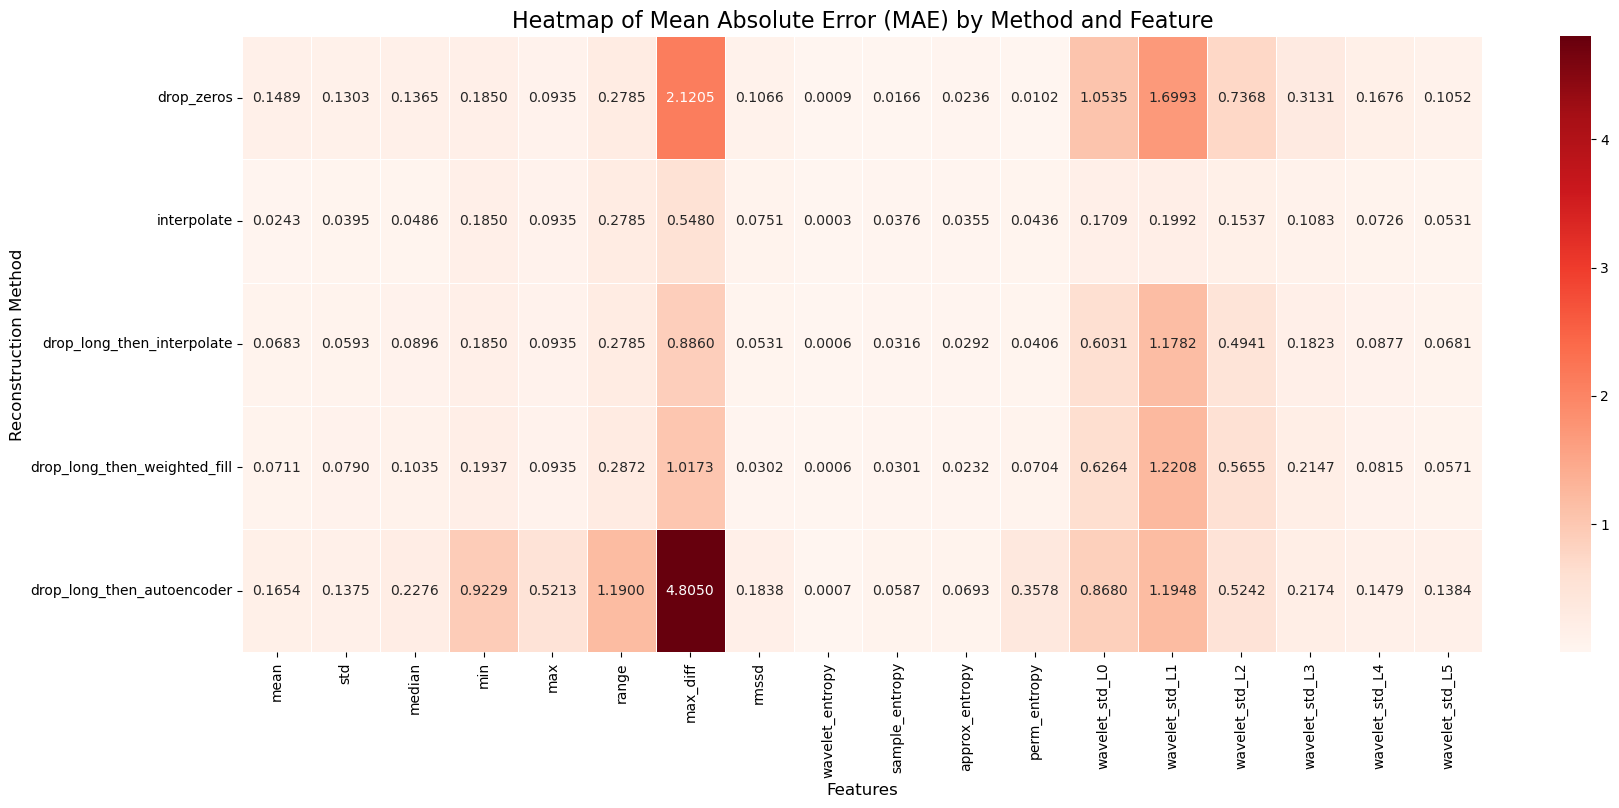

In [ ]:
# Heatmap of MAE 

plt.figure(figsize=(20, 8))
sns.heatmap(
    error_df,
    annot=True,
    fmt=".4f",
    cmap="Reds",
    linewidths=0.5
)
plt.title("Heatmap of Mean Absolute Error (MAE) by Method and Feature", fontsize=16)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Reconstruction Method", fontsize=12)
plt.show()


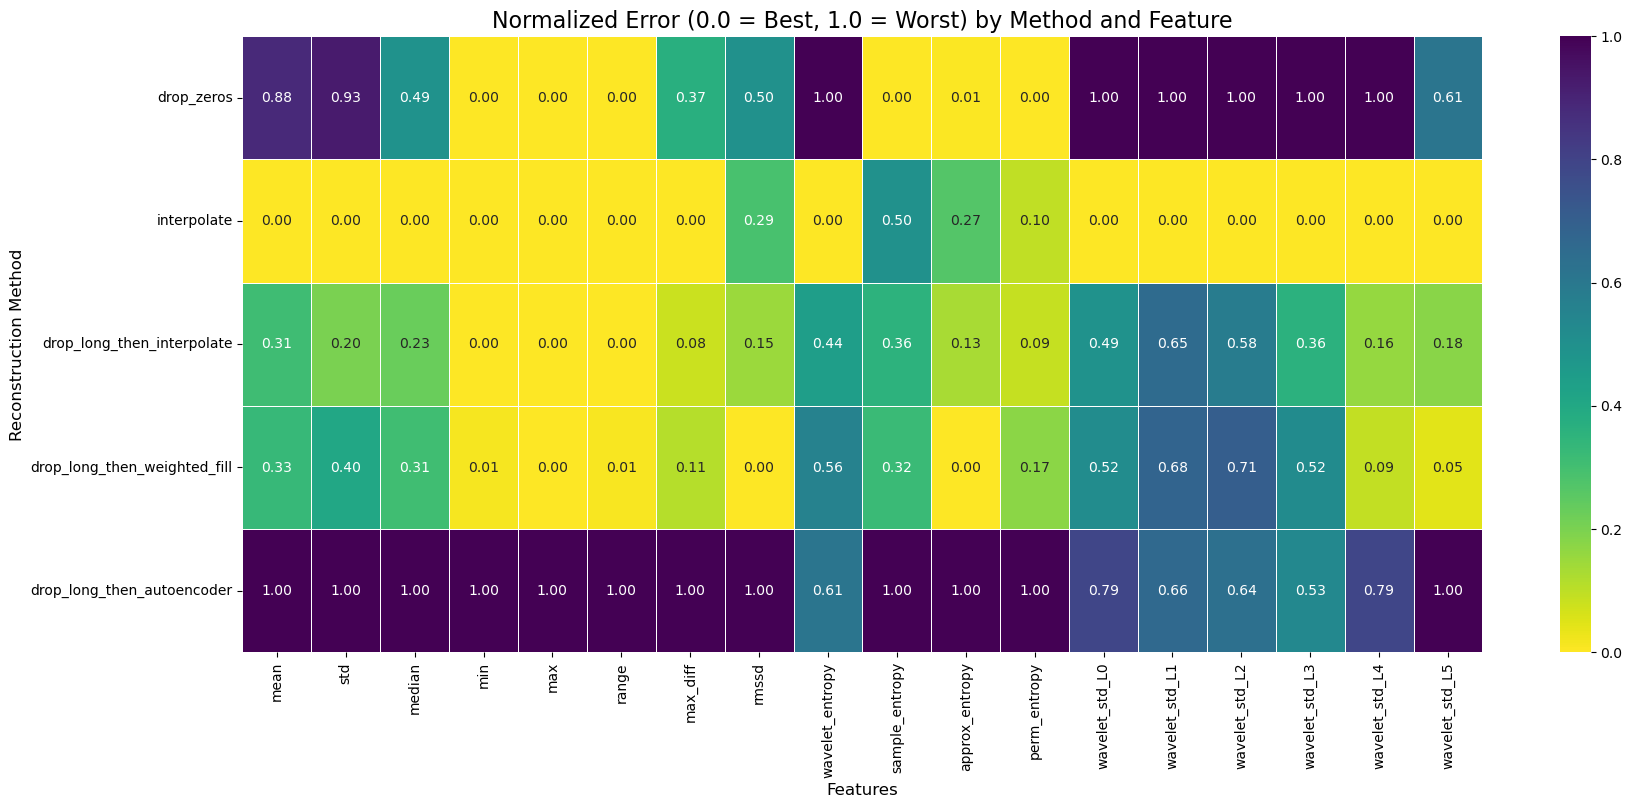

In [ ]:
# Normalized heatmap
normalized_error_df = error_df.apply(lambda x: (x - x.min()) / (x.max() - x.min()), axis=0)

plt.figure(figsize=(20, 8))
sns.heatmap(
    normalized_error_df,
    annot=True,
    fmt=".2f",
    cmap="viridis_r",
    linewidths=0.5
)
plt.title("Normalized Error (0.0 = Best, 1.0 = Worst) by Method and Feature", fontsize=16)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Reconstruction Method", fontsize=12)
plt.show()

In [15]:
normalized_error_df

,mean,std,median,min,max,range,max_diff,rmssd,wavelet_entropy,sample_entropy,approx_entropy,perm_entropy,wavelet_std_L0,wavelet_std_L1,wavelet_std_L2,wavelet_std_L3,wavelet_std_L4,wavelet_std_L5
drop_zeros,0.882890,0.926374,0.491240,0.000000,0.0,0.000000,0.369392,0.497118,1.000000,0.000000,0.007809,0.000000,1.000000,1.000000,1.000000,1.00000,1.000000,0.611102
interpolate,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.292147,0.000000,0.498360,0.266269,0.095951,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
drop_long_then_interpolate,0.311496,0.201731,0.229259,0.000000,0.0,0.000000,0.079399,0.149141,0.441692,0.357506,0.130323,0.087374,0.489726,0.652626,0.583819,0.36139,0.159484,0.175838
drop_long_then_weighted_fill,0.331635,0.402931,0.307114,0.011736,0.0,0.009501,0.110253,0.000000,0.560653,0.320412,0.000000,0.173154,0.516067,0.680977,0.706164,0.51963,0.093641,0.046110
drop_long_then_autoencoder,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,1.000000,1.000000,0.613231,1.000000,1.000000,1.000000,0.789789,0.663654,0.635447,0.53265,0.792447,1.000000
